# Does steering pick ideas or spread them?

This notebook demonstrates `method.py` from the experiment **"Does steering pick ideas or spread them?"**.

**The question.** If you ask an instruction-tuned LLM to *"Implement a sorting algorithm"*, it nearly always writes
**Bubble sort** (Qwen2.5-3B-Instruct: ~62% of 300 samples at T=0.7). Can we get *other ideas* out of it by pushing on its
activations? There are two possibilities:

* **SELECT**: the steering vector moves the model to a *specific* other idea (e.g. Quick sort).
* **FLATTEN**: the steering vector spreads probability over many ideas, which looks like turning up the temperature.

**What the full experiment did (GPU, ~3 h):**
1. *Step A*: re-analysed an earlier influence arm. Targeted vs random steering entropy, hierarchical bootstrap.
2. *Step B (Qwen2.5-3B-Instruct)*: took the commitment-window activations and built a difference-in-means direction
   `d_away` ("away from the mode idea"). It then compared that direction with **5 random directions of the same norm**,
   with per-idea directions `d_j`, with prompting (`"... using heap sort."`) and with temperature. The decision rules
   were frozen (SHA256) before the main sweep.
3. *Step C (gemma-2-2b-it)*: ban-displacement geometry, temperature law, Δh transplant, SAE description.

`method.py` itself is the **entry point**. It (a) runs the pipeline stages listed in `STAGES` as subprocesses and
(b) `build_output()` joins every generation (`data/gens/...`) with its label and oracle score (`data/scored/...`) into
`method_out.json`, flagging *off-menu correct* solutions (a working sort that is not one of the 4 "menu" ideas).

**What this demo runs (CPU, seconds).** The GPU stages need the 3B/2B models and a 16 GB GPU, so they are **not**
re-run here. Instead the notebook loads a curated subset of the real Qwen T2 generations and their scores (100
examples, 10 settings, same seeds across settings). It writes them back into the on-disk layout `method.py` expects
and runs the original `build_output()` **unchanged**. It then summarises SELECT vs FLATTEN with the experiment's own
statistics (Miller-Madow entropy, Wilson CIs, hierarchical draw→sample bootstrap).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab -> always install
_pip('loguru==0.7.3')

# numpy, matplotlib: pre-installed on Colab -> install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
# ---- original import block of method.py ----
from __future__ import annotations

import json
import subprocess
import sys
from pathlib import Path

from loguru import logger

# ---- extra imports for the helpers copied from src/common.py and for the visualisation ----
import math
import os
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-8d19e3-temperature-flattens-ideas-context/main/round-2/experiment-6/demo/mini_demo_data.json"
import json
from pathlib import Path

def load_data():
    try:
        import urllib.request
        with urllib.request.urlopen(GITHUB_DATA_URL) as response:
            return json.loads(response.read().decode())
    except Exception: pass
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
ds = data["datasets"][0]
print("dataset:", ds["dataset"], "| model:", data["metadata"]["model"], "| task:", data["metadata"]["task"])
print("examples per setting:", {s: len(v) for s, v in ds["gens"].items()})

dataset: qwen_T2_sorting | model: Qwen/Qwen2.5-3B-Instruct | task: T2
examples per setting: {'baseline': 16, 'away_s2': 16, 'rand0_s2': 5, 'rand1_s2': 5, 'rand2_s2': 5, 'rand3_s2': 5, 'rand4_s2': 5, 'dj_Heap_s2': 14, 'forced_Heap': 14, 'temp1.3': 15}


## Configuration

All tunable parameters live here. The full experiment used 300 baseline seeds and 150 seeds per steered or random
setting, with `B = 10000` bootstrap replicates. The demo file holds at most 16 seeds per setting (5 per random draw),
so `N_PER_SETTING` caps how many of those are used.

In [5]:
N_PER_SETTING = 16      # max seeds used per setting (demo file holds <= 16; original run: 300 baseline / 150 per setting)
N_BOOT = 2000           # hierarchical-bootstrap replicates (original: 10000)
BOOT_SEED = 20261016    # bootstrap RNG seed used by the original analysis
RUN_GPU_STAGES = False  # the STAGES of method.py need src/*.py + a 16 GB GPU + model downloads; not run in the demo
WORKDIR = Path("demo_workspace")  # plays the role of the artifact folder (ROOT)

## Shared paths, I/O and statistics (from `src/common.py`)

`method.py` imports `P4_MENU, RESULTS, SCORED, GENS, read_jsonl, write_json` from `src/common.py`. The relevant parts of
that module are copied verbatim below. `ROOT` points at a local `demo_workspace/` folder instead of the artifact
directory. The statistics (`entropy_mm`, `wilson`, `hier_boot`, ...) are the ones every verdict of the experiment
uses, and the results cell at the end reuses them.

* `P4_MENU`: the four "menu" ideas per task. A solution that passes the oracle but is **not** on the menu counts as
  *off-menu correct* (a crude "novelty" signal).
* `MODE`: the default idea the model falls back on (T1: BFS, T2: Bubble).

In [6]:
ROOT = WORKDIR.resolve()
SRC = ROOT / "src"
DATA = ROOT / "data"
GENS = DATA / "gens"          # gens/<model>/<task>/<setting>.jsonl
SCORED = DATA / "scored"      # scored/<model>/<task>/<setting>.jsonl
ACTS = DATA / "acts"
RESULTS = ROOT / "results"
FIGS = ROOT / "figs"
LOGS = ROOT / "logs"
for _d in (GENS, SCORED, ACTS, RESULTS, FIGS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

QWEN = "Qwen/Qwen2.5-3B-Instruct"
GEMMA = "google/gemma-2-2b-it"
MODEL_TAG = {QWEN: "qwen", GEMMA: "gemma"}
P4_MENU = {"T1": ["BFS", "DFS", "A_star", "Dijkstra"], "T2": ["Bubble", "Quick", "Merge", "Selection"]}
MODE = {"T1": "BFS", "T2": "Bubble"}


# ----------------------------------------------------------------------------------------------- I/O
def read_jsonl(p: Path) -> list[dict]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    for line in p.read_text().splitlines():
        if line.strip():
            try:
                out.append(json.loads(line))
            except json.JSONDecodeError:
                continue  # a partially written trailing line after an interruption
    return out


def append_jsonl(p: Path, rows: list[dict]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")


def write_json(p: Path, obj) -> None:
    Path(p).parent.mkdir(parents=True, exist_ok=True)
    Path(p).write_text(json.dumps(obj, indent=1, default=_json_default))


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, tuple)):
        return list(o)
    raise TypeError(type(o))


# ----------------------------------------------------------------------------------------------- statistics
def entropy_bits(labels) -> float:
    c = np.array(list(Counter(labels).values()), float)
    if c.sum() == 0:
        return float("nan")
    p = c / c.sum()
    return float(-(p * np.log2(p)).sum())


def entropy_mm(labels) -> float:
    """Miller-Madow bias-corrected plug-in entropy (bits): H + (K_obs-1)/(2 n ln 2)."""
    n = len(labels)
    if n == 0:
        return float("nan")
    k = len(set(labels))
    return entropy_bits(labels) + (k - 1) / (2 * n * math.log(2))


def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


# ----------------------------------------------------------------------------------------------- vectorized bootstrap
def encode(groups: list[list], exclude: set | None = None) -> tuple[list[np.ndarray], list]:
    """Map labels to ints (shared vocabulary); excluded (non-idea) labels -> -1."""
    exclude = exclude or set()
    vocab = sorted({x for g in groups for x in g if x not in exclude}, key=str)
    ix = {v: i for i, v in enumerate(vocab)}
    return [np.array([ix.get(x, -1) for x in g], int) for g in groups], vocab


def _stat_rows(M: np.ndarray, K: int, stat: str) -> np.ndarray:
    """M: [R, n] int labels (-1 = excluded) or 0/1 values for 'mean'. Returns stat per row."""
    if stat == "mean":
        return M.mean(1)
    oh = np.zeros((M.shape[0], K), float)
    for k in range(K):
        oh[:, k] = (M == k).sum(1)
    n = oh.sum(1, keepdims=True)
    p = np.divide(oh, n, out=np.zeros_like(oh), where=n > 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.nansum(np.where(p > 0, p * np.log2(p), 0.0), 1)
    if stat == "H_mm":
        kobs = (oh > 0).sum(1)
        h = h + (kobs - 1) / (2 * np.maximum(n[:, 0], 1) * math.log(2))
    return h


def stat_point(x: np.ndarray, K: int, stat: str) -> float:
    return float(_stat_rows(x[None, :], K, stat)[0])


def _boot_matrix(x: np.ndarray, K: int, stat: str, B: int, m: int, rng) -> np.ndarray:
    """[B, m] independent within-sample bootstrap stats of one cell."""
    n = len(x)
    out = np.empty((B, m))
    for j in range(m):
        idx = rng.integers(0, n, (B, n))
        out[:, j] = _stat_rows(x[idx], K, stat)
    return out


def hier_boot(target: list[np.ndarray], draws: list[np.ndarray], K: int, stat: str, B: int = 10000,
              seed: int = 20261016) -> dict:
    """Hierarchical bootstrap of mean_t stat(target_t) - mean_d stat(draw_d).

    Each arm with >1 draw: resample draws with replacement, then samples within each chosen draw
    (independent resamples per slot). Single-draw arms: resample samples only."""
    rng = np.random.default_rng(seed)

    def arm(cells):
        m = len(cells)
        mats = [_boot_matrix(c, K, stat, B, m, rng) for c in cells]
        if m == 1:
            return mats[0][:, 0]
        pick = rng.integers(0, m, (B, m))
        vals = np.stack([np.stack(mats, 0)[pick[:, j], np.arange(B), j] for j in range(m)], 1)
        return vals.mean(1)
    bt, br = arm(target), arm(draws)
    d = bt - br
    pt = float(np.mean([stat_point(c, K, stat) for c in target]))
    pr_each = [stat_point(c, K, stat) for c in draws]
    pr = float(np.mean(pr_each))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return dict(target=pt, random_draw_mean=pr, random_per_draw=pr_each, diff=pt - pr, ci=[float(lo), float(hi)],
                p_gt0=float((d > 0).mean()), B=B, n_target=[len(c) for c in target], n_draws=[len(c) for c in draws],
                verdict=("beats" if lo > 0 else "below" if hi < 0 else "undetermined"))

## Materialise the demo data in the layout `method.py` reads

In the original run the GPU stages write one JSONL file per setting:

* `data/gens/qwen/T2/<setting>.jsonl`: the generation (`user_message`, `text`, `seed`, `T`, `topk`, `iv` = the
  intervention, e.g. `{"kind": "add", "vec": "d_away", "alpha": 0.473}`).
* `data/scored/qwen/T2/<setting>.jsonl`: the idea label from the v1 classifier, plus the oracle status (whether the
  extracted Python function really sorts).

`results/verdicts.json` and `results/deviations.json` are read into the output metadata. This cell writes the
loaded `data` back to exactly those paths, keeping the first `N_PER_SETTING` seeds per setting. Nothing about
`build_output()` has to change.

**Settings in the demo** (strength `s2` corresponds to α = 0.473 × the activation norm):

| setting | what it is |
|---|---|
| `baseline` | plain prompt, T = 0.7 |
| `away_s2` | targeted steering along `d_away` (difference-in-means: non-Bubble minus Bubble) |
| `rand0_s2` … `rand4_s2` | 5 random directions with the **same norm** (the FLATTEN control) |
| `dj_Heap_s2` | steering towards an off-menu idea (`d_j` for Heap sort) |
| `forced_Heap` | prompting instead of steering: "*... using heap sort.*" |
| `temp1.3` | no steering, temperature 1.3 (the "creativity knob") |

In [7]:
model, task = "qwen", data["metadata"]["task"]
for setting, rows in ds["gens"].items():
    keep = sorted(rows, key=lambda r: r["seed"])[:N_PER_SETTING]
    seeds = {r["seed"] for r in keep}
    for sub, src_rows in ((GENS, keep), (SCORED, [r for r in ds["scored"][setting] if r["seed"] in seeds])):
        p = sub / model / task / f"{setting}.jsonl"
        p.parent.mkdir(parents=True, exist_ok=True)
        p.write_text("".join(json.dumps(r) + "\n" for r in src_rows))
write_json(RESULTS / "verdicts.json", data["metadata"]["verdicts"])
write_json(RESULTS / "deviations.json", data["metadata"]["deviations"])
(ROOT / "logs").mkdir(exist_ok=True)
print(sorted(str(p.relative_to(ROOT)) for p in (GENS / model / task).glob("*.jsonl")))

['data/gens/qwen/T2/away_s2.jsonl', 'data/gens/qwen/T2/baseline.jsonl', 'data/gens/qwen/T2/dj_Heap_s2.jsonl', 'data/gens/qwen/T2/forced_Heap.jsonl', 'data/gens/qwen/T2/rand0_s2.jsonl', 'data/gens/qwen/T2/rand1_s2.jsonl', 'data/gens/qwen/T2/rand2_s2.jsonl', 'data/gens/qwen/T2/rand3_s2.jsonl', 'data/gens/qwen/T2/rand4_s2.jsonl', 'data/gens/qwen/T2/temp1.3.jsonl']


## `method.py`: logging and the pipeline stages

This is the original module-level setup. `STAGES` documents the whole pipeline in the order it actually ran
(A reanalysis → B Qwen steering → C gemma bans/temperature/transplant → analyses → figures → verify). `run_stage`
launches each stage as a subprocess in the artifact folder. Every stage is resumable.

The demo **does not execute** these stages (`RUN_GPU_STAGES = False`): they need the `src/` package, model weights
(Qwen2.5-3B-Instruct, gemma-2-2b-it, Gemma Scope SAE) and about 3 GPU-hours. The table is printed so you can see what
produced the data used below.

In [8]:
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(ROOT / "logs" / "method.log", rotation="30 MB", level="DEBUG")

PY = sys.executable
STAGES = {
    "A": ["src/reanalysis.py"],
    "codestop": ["tests/check_codestop.py"],
    "B_base": ["src/steer_qwen.py", "base", "--batch", "200"],
    "B_acts": ["src/steer_qwen.py", "acts"],
    "B_vectors": ["src/steer_qwen.py", "vectors"],
    "B_freeze": ["src/steer_qwen.py", "freeze"],
    "B_calib": ["src/steer_qwen.py", "calib", "--batch", "200"],
    "B_freeze2": ["src/steer_qwen.py", "freeze2"],
    "B_main": ["src/steer_qwen.py", "main", "--batch", "200"],
    "B_score_ba": ["src/score_ba.py", "2"],
    "B_analyze": ["src/analyze_qwen.py"],
    "C_screen_a": ["src/gemma.py", "screen_a", "--nb", "150", "--npl", "50", "--batch", "75", "--max_new", "768"],
    "C_screen_b": ["src/gemma.py", "screen_b", "--nf", "20", "--nban", "50", "--batch", "75", "--max_new", "768"],
    "C_audit": ["src/audit.py"],
    "C_geometry": ["src/gemma.py", "geometry"],
    "C_confirm": ["src/gemma.py", "confirm", "--nconf", "50", "--batch", "75", "--max_new", "768"],
    "C_confirm_states": ["src/gemma.py", "confirm_states"],
    "C_temp": ["src/gemma.py", "temp", "--ntemp", "40", "--batch", "75", "--max_new", "768"],
    "C_transplant": ["src/gemma.py", "transplant", "--ntr", "30", "--batch", "75", "--max_new", "768"],
    "C_analyze": ["src/analyze_gemma.py"],
    "figures": ["src/figures.py"],
    "verify": ["verify.py"],
}


def run_stage(name: str) -> None:
    cmd = [PY] + STAGES[name]
    logger.info(f"stage {name}: {' '.join(cmd)}")
    subprocess.run(cmd, cwd=ROOT, check=True)


for name, cmd in STAGES.items():
    print(f"{name:18s} python {' '.join(cmd)}")
if RUN_GPU_STAGES:  # only meaningful inside the full artifact folder with a GPU
    for name in STAGES:
        run_stage(name)

A                  python src/reanalysis.py
codestop           python tests/check_codestop.py
B_base             python src/steer_qwen.py base --batch 200
B_acts             python src/steer_qwen.py acts
B_vectors          python src/steer_qwen.py vectors
B_freeze           python src/steer_qwen.py freeze
B_calib            python src/steer_qwen.py calib --batch 200
B_freeze2          python src/steer_qwen.py freeze2
B_main             python src/steer_qwen.py main --batch 200
B_score_ba         python src/score_ba.py 2
B_analyze          python src/analyze_qwen.py
C_screen_a         python src/gemma.py screen_a --nb 150 --npl 50 --batch 75 --max_new 768
C_screen_b         python src/gemma.py screen_b --nf 20 --nban 50 --batch 75 --max_new 768
C_audit            python src/audit.py
C_geometry         python src/gemma.py geometry
C_confirm          python src/gemma.py confirm --nconf 50 --batch 75 --max_new 768
C_confirm_states   python src/gemma.py confirm_states
C_temp             pyt

## `method.py`: `build_output()`

This is the original output builder. For every model × task folder and every setting it joins each generation with its
score **by seed** and skips the `smoke` file. It derives:

* `predict_idea_label_v1`: which algorithm was written (Bubble, Quick, Merge, Heap, ...);
* `metadata_offmenu_correct`: the oracle passed **and** the idea is not one of the 4 menu ideas (nor `Unparseable`);
* `metadata_offmenu_correct_excl_builtin`: the same, but calling `sorted()` does not count.

It then attaches the verdicts, the Step-A summary, the frozen pre-registration hashes and the deviations as metadata.

*Only change:* the line `from protocol import user_message` is commented out. It is an unused import ("kept for
reference of the prompt builder") and `src/protocol.py` is not shipped with the demo. For reference, the T2 prompt is
`"Implement a sorting algorithm"`, and the forced variant appends `" using heap sort."`.

In [9]:
def _load(p: Path) -> dict:
    return json.loads(p.read_text()) if p.exists() else {}


def build_output() -> None:
    # from protocol import user_message  # noqa: F401  (kept for reference of the prompt builder)
    datasets = []
    n_total = 0
    for model in ("qwen", "gemma"):
        for task in ("T1", "T2"):
            gdir = GENS / model / task
            if not gdir.exists():
                continue
            ex = []
            for gp in sorted(gdir.glob("*.jsonl")):
                setting = gp.stem
                if setting == "smoke":
                    continue
                sc = {r["seed"]: r for r in read_jsonl(SCORED / model / task / f"{setting}.jsonl")}
                for g in read_jsonl(gp):
                    s = sc.get(g["seed"])
                    if s is None:
                        continue
                    lab = s["label"]
                    menu = set(P4_MENU[task]) | {"Unparseable"}
                    off = bool(s["oracle_pass"] and lab not in menu)
                    ex.append({
                        "input": g["user_message"], "output": g["text"],
                        "predict_idea_label_v1": lab, "predict_oracle_status": s["oracle_status"],
                        "metadata_task": task, "metadata_model": model, "metadata_condition": setting,
                        "metadata_family": g.get("family", ""), "metadata_seed": g["seed"],
                        "metadata_temperature": g.get("T"), "metadata_topk": g.get("topk"),
                        "metadata_intervention": json.dumps(g.get("iv")) if g.get("iv") else "",
                        "metadata_label_v1": lab, "metadata_oracle_status": s["oracle_status"],
                        "metadata_pass_frac": s["pass_frac"], "metadata_offmenu_correct": off,
                        "metadata_offmenu_correct_excl_builtin": off and lab != "Builtin",
                        "metadata_truncated": g["hit_max"], "metadata_ntoks": g["ntoks"]})
            if ex:
                datasets.append({"dataset": f"{model}_{task}_{'path_search' if task == 'T1' else 'sorting'}",
                                 "examples": ex})
                n_total += len(ex)
    meta = dict(
        method_name="Does steering pick ideas or spread them? Selector steering (Qwen2.5-3B-Instruct) vs matched-norm "
                    "random draws, and a displacement logit for bans (gemma-2-2b-it)",
        models=["Qwen/Qwen2.5-3B-Instruct", "google/gemma-2-2b-it"], n_examples=n_total,
        verdicts=_load(RESULTS / "verdicts.json"),
        A_reanalysis=_summ_A(_load(RESULTS / "reanalysis_contract.json")),
        frozen_hashes={p.name: p.read_text().split()[0] for p in sorted(RESULTS.glob("frozen_*.sha256"))},
        deviations=_load(RESULTS / "deviations.json"),
        audit_cost_usd=_load(RESULTS / "audit.json").get("cost_usd"),
        result_files=sorted(p.name for p in RESULTS.glob("*.json")))
    out = {"metadata": meta, "datasets": datasets}
    (ROOT / "method_out.json").write_text(json.dumps(out))
    logger.info(f"method_out.json: {n_total} examples in {len(datasets)} datasets")


def _summ_A(a: dict) -> dict:
    if not a:
        return {}
    return dict(status=a.get("status"), claim3_verdict=a.get("claim3", {}).get("verdict"),
                claim3_counts_primary=a.get("claim3", {}).get("counts", {}).get(a.get("claim3", {}).get("primary_spec")),
                a4={t: {k: a["a4"][t][k] for k in ("rho", "exact_p_two_sided", "exact_p_one_sided_positive",
                                                   "original_ci", "ci_corrected")} for t in ("T1", "T3")},
                file_counts={t: {k: v for k, v in a["file_counts"][t].items() if k.startswith("n_") or k ==
                                 "gens_without_scored"} for t in ("T1", "T3")})

### Run it (equivalent to `python method.py output`)

In [10]:
build_output()
out = json.loads((ROOT / "method_out.json").read_text())
examples = out["datasets"][0]["examples"]
print(out["datasets"][0]["dataset"], "->", len(examples), "examples;", "result files in metadata:",
      out["metadata"]["result_files"])
ex0 = next(e for e in examples if e["metadata_condition"] == "away_s2")
print("\nOne steered example:", {k: ex0[k] for k in ("metadata_condition", "metadata_intervention",
                                                    "predict_idea_label_v1", "predict_oracle_status",
                                                    "metadata_offmenu_correct")})
print(ex0["output"][:600], "...")

07:44:59|INFO   |method_out.json: 100 examples in 1 datasets


qwen_T2_sorting -> 100 examples; result files in metadata: ['deviations.json', 'verdicts.json']

One steered example: {'metadata_condition': 'away_s2', 'metadata_intervention': '{"kind": "add", "vec": "d_away", "alpha": 0.473}', 'predict_idea_label_v1': 'Quick', 'predict_oracle_status': 'pass', 'metadata_offmenu_correct': False}
Certainly! There are many sorting algorithms, each with its own advantages and complexities. Let's implement the Quicksort algorithm, which is a divide-and-conquer algorithm. Quicksort is widely used because of its average-case efficiency.

Quicksort works by selecting a 'pivot' element from the array and partitioning the other elements into two sub-arrays, according to whether they are less than or greater than the pivot. The sub-arrays are then recursively sorted.

Here is a Python implementation of Quicksort:

```python
def quicksort(arr):
    if len(arr) <= 1:
        return arr
    else:
 ...


## Results: does steering SELECT or FLATTEN?

The cell below groups the `method_out.json` examples by setting. For each setting it reports:

* **Bubble share**: how often the default (mode) idea is still written;
* **top non-mode idea**: the most frequent other idea and its share. *SELECT* means one specific idea takes over;
* **H_mm**: Miller-Madow entropy of the idea distribution in bits. *FLATTEN* means entropy goes **up**;
* **pass**: the share of solutions whose extracted function passes the sorting oracle;
* **off-menu ✓**: correct solutions that are not Bubble/Quick/Merge/Selection.

It then runs the experiment's **hierarchical bootstrap**: targeted `d_away` against the mean over the 5 matched-norm
random draws, on entropy and on non-mode share. Finally it prints the full-scale numbers (n = 150–300 per setting)
stored in the data file next to the demo's small-n estimates, plus the full-run T2 selector verdict. With 5–16 seeds per cell the demo's CIs are wide, so
read the trend and use the full-scale columns for the actual verdicts.

In [11]:
NONIDEA = {"Unparseable"}
by = {}
for e in examples:
    by.setdefault(e["metadata_condition"], []).append(e)
order = ["baseline", "temp1.3", "rand0_s2", "rand1_s2", "rand2_s2", "rand3_s2", "rand4_s2", "away_s2",
         "dj_Heap_s2", "forced_Heap"]
order = [s for s in order if s in by]
ref = data["metadata"]["full_scale_reference"]

def summ(rows):
    L = [r["predict_idea_label_v1"] for r in rows if r["predict_idea_label_v1"] not in NONIDEA]
    n = len(rows); c = Counter(L)
    nm = {k: v for k, v in c.items() if k != MODE["T2"]}
    top = max(nm, key=nm.get) if nm else "-"
    return dict(n=n, bubble=c.get("Bubble", 0) / n, top=top, top_share=(nm[top] / n if nm else 0.0),
                H=entropy_mm(L), pass_=sum(r["predict_oracle_status"] == "pass" for r in rows) / n,
                off=sum(r["metadata_offmenu_correct"] for r in rows), counts=c)

print(f"{'setting':12s} {'n':>3s} {'Bubble':>7s} {'Wilson95':>13s} {'top non-mode':>18s} {'H_mm':>5s} {'pass':>5s} "
      f"{'off✓':>4s} | {'FULL n':>6s} {'Bubble':>7s} {'top non-mode':>18s} {'pass':>5s}")
S = {}
for s in order:
    m = S[s] = summ(by[s])
    lo, hi = wilson(round(m["bubble"] * m["n"]), m["n"])
    f = ref[s]; fc = f["counts"]; fn = f["n"]
    fnm = {k: v for k, v in fc.items() if k not in ("Bubble", "Unparseable")}
    ftop = max(fnm, key=fnm.get) if fnm else "-"
    print(f"{s:12s} {m['n']:3d} {m['bubble']:7.0%} [{lo:4.0%},{hi:4.0%}] {m['top']:>11s} {m['top_share']:5.0%} "
          f"{m['H']:5.2f} {m['pass_']:5.0%} {m['off']:4d} | {fn:6d} {fc.get('Bubble', 0) / fn:7.0%} "
          f"{ftop:>11s} {fnm.get(ftop, 0) / fn:5.0%} {f['pass_rate']:5.0%}")

# targeted d_away vs the 5 matched-norm random draws (hierarchical draw -> sample bootstrap, as in analyze_qwen.py)
rand = [s for s in order if s.startswith("rand")]
if "away_s2" in by and rand:
    groups = [[r["predict_idea_label_v1"] for r in by[s]] for s in ["away_s2"] + rand]
    enc, vocab = encode(groups, exclude=NONIDEA)
    hb_H = hier_boot([enc[0]], enc[1:], len(vocab), "H_mm", B=N_BOOT, seed=BOOT_SEED)
    nm = [np.array([float(x not in NONIDEA and x != MODE["T2"]) for x in g]) for g in groups]
    hb_nm = hier_boot([nm[0]], nm[1:], 1, "mean", B=N_BOOT, seed=BOOT_SEED)
    for name, hb in (("entropy H_mm", hb_H), ("non-mode share", hb_nm)):
        print(f"\nd_away vs random draws, {name}: target={hb['target']:.2f}  draw-mean={hb['random_draw_mean']:.2f}  "
              f"diff={hb['diff']:+.2f}  95% CI [{hb['ci'][0]:+.2f}, {hb['ci'][1]:+.2f}]  -> {hb['verdict']}")

vb = data["metadata"]["verdicts"]
bt2 = vb["B_selector"]["T2"]
print("\nFULL RUN (results/verdicts.json, n=150/cell, B=10000) T2 selector decision:", bt2["decision"],
      "| predicted gainers:", bt2["predicted_gainers"])
for k in ("main@s2", "redraw@s2"):
    e, m = bt2["entropy_vs_random_draw_mean"][k], bt2["nonmode_share_vs_random"][k]
    print(f"  {k:10s} entropy diff {e['diff']:+.2f} CI [{e['ci'][0]:+.2f},{e['ci'][1]:+.2f}] ({e['verdict']}) | "
          f"non-mode share diff {m['diff']:+.2f} CI [{m['ci'][0]:+.2f},{m['ci'][1]:+.2f}]")
print("All verdict groups:", list(vb))

setting        n  Bubble      Wilson95       top non-mode  H_mm  pass off✓ | FULL n  Bubble       top non-mode  pass
baseline      16     56% [ 33%, 77%]       Quick   38%  1.34  100%    0 |    300     62%       Quick   23%   98%
temp1.3       15     47% [ 25%, 70%]       Quick   33%  1.83   80%    1 |    150     47%       Quick   25%   81%
rand0_s2       5      0% [  0%, 43%]       Quick   60%  1.66  100%    0 |    150     22%       Quick   50%   97%
rand1_s2       5     20% [  4%, 62%]       Quick   80%  0.87  100%    0 |    150     57%       Quick   31%   99%
rand2_s2       5     60% [ 23%, 88%]       Merge   20%  1.66  100%    0 |    150     69%       Merge   15%   98%
rand3_s2       5      0% [  0%, 43%]   Selection   60%  1.66  100%    0 |    150     19%   Selection   48%   98%
rand4_s2       5     20% [  4%, 62%]       Merge   40%  2.35  100%    1 |    150     40%       Merge   34%   99%
away_s2       16      0% [  0%, 19%]       Quick   62%  1.29   94%    0 |    150      1%    


d_away vs random draws, entropy H_mm: target=1.29  draw-mean=1.64  diff=-0.35  95% CI [-0.71, +0.67]  -> undetermined

d_away vs random draws, non-mode share: target=1.00  draw-mean=0.80  diff=+0.20  95% CI [+0.00, +0.44]  -> undetermined

FULL RUN (results/verdicts.json, n=150/cell, B=10000) T2 selector decision: {'main': 'SELECT', 'redraw': 'SELECT', 'verdict': 'SELECT'} | predicted gainers: ['Quick', 'Selection']
  main@s2    entropy diff -0.71 CI [-0.94,-0.44] (below) | non-mode share diff +0.41 CI [+0.23,+0.58]
  redraw@s2  entropy diff -0.73 CI [-0.95,-0.45] (below) | non-mode share diff +0.41 CI [+0.24,+0.58]
All verdict groups: ['A_claim3', 'A_a4', 'A_file_counts', 'B_selector', 'B_C4_qwen', 'frozen_hashes_qwen', 'C2a_jsd_gain', 'C2b_top_substitute', 'C_regularity', 'C_screen_noise_floor_pp', 'C_frozen', 'C_frozen_sha256', 'C1_temperature', 'C2c_transplant', 'C1_audit', 'D_sae']


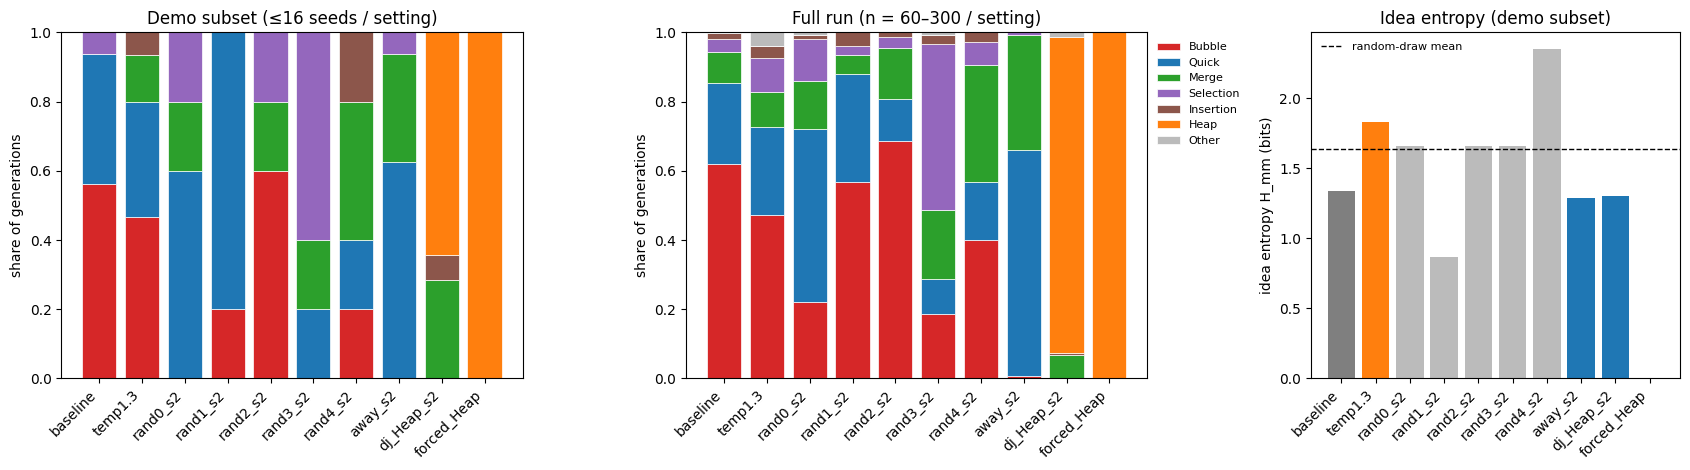

In [12]:
# Stacked idea distributions per setting (demo subset) next to the full-scale run
ideas = ["Bubble", "Quick", "Merge", "Selection", "Insertion", "Heap", "Other"]
colors = ["#d62728", "#1f77b4", "#2ca02c", "#9467bd", "#8c564b", "#ff7f0e", "#bbbbbb"]

def shares(c, n):
    v = [c.get(k, 0) / n for k in ideas[:-1]]
    return v + [max(0.0, 1 - sum(v))]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
for ax, title, get in ((axes[0], f"Demo subset (≤{N_PER_SETTING} seeds / setting)",
                        lambda s: shares(S[s]["counts"], S[s]["n"])),
                       (axes[1], "Full run (n = 60–300 / setting)",
                        lambda s: shares(ref[s]["counts"], ref[s]["n"]))):
    bottom = np.zeros(len(order))
    for k, (idea, col) in enumerate(zip(ideas, colors)):
        vals = np.array([get(s)[k] for s in order])
        ax.bar(range(len(order)), vals, bottom=bottom, color=col, label=idea, edgecolor="white", linewidth=0.5)
        bottom += vals
    ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
    ax.set_ylabel("share of generations"); ax.set_ylim(0, 1); ax.set_title(title)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)

# entropy: targeted vs each random draw vs baseline / temperature (demo subset)
ent = [S[s]["H"] for s in order]
cols = ["#7f7f7f" if s == "baseline" else "#ff7f0e" if s.startswith("temp") else "#bbbbbb" if s.startswith("rand")
        else "#1f77b4" for s in order]
axes[2].bar(range(len(order)), ent, color=cols)
if rand:
    axes[2].axhline(np.mean([S[s]["H"] for s in rand]), ls="--", color="k", lw=1, label="random-draw mean")
    axes[2].legend(fontsize=8, frameon=False)
axes[2].set_xticks(range(len(order)), order, rotation=45, ha="right")
axes[2].set_ylabel("idea entropy H_mm (bits)"); axes[2].set_title("Idea entropy (demo subset)")
plt.tight_layout(); plt.show()

### How to read this

* **Baseline**: Bubble sort dominates. This is the model's "average answer".
* **Temperature 1.3**: Bubble is still the mode and the other ideas get only a little more mass. In the full run
  Bubble falls from 62% to 47%. Turning the "creativity knob" barely changes *which* ideas come out.
* **Random directions (same norm)**: these also move the distribution, sometimes a lot (full run: `rand0` pushes
  Quick to 50%, `rand3` pushes Selection to 48%). The direction is arbitrary, though, and Bubble keeps about 41% on
  average across the 5 draws. A generic push of this size already reshuffles the menu.
* **`d_away`**: Bubble almost disappears (full run 62% → 0–1%), and the mass moves to **Quick** (65–68%, the frozen
  predicted gainer) and Merge, with pass rate about 0.92. Relative to the random-draw mean, the non-mode share is
  +0.41 and entropy is 0.71 bits *lower*. The direction **selects** rather than spreads.
* **`d_Heap` vs prompting**: steering towards an off-menu idea works for Heap sort (91%). For the other off-menu
  ideas in the full run (Counting, IDDFS, Bellman-Ford) steering gave 0–1%, while asking for them in the prompt gave
  92–100%. For off-menu ideas, the prompt usually beats the activation push.

The full-run verdicts in `results/verdicts.json` (embedded in the data file and shown above as keys) come from the
complete n = 150–300 cells with B = 10,000 bootstrap replicates. They also cover T1 path search and the gemma
ban-displacement, temperature-law and transplant tests, which need a GPU.